# Building a Health-Domain Language Model — on Apple Silicon

**ICS554 Natural Language Processing · Prosit 1, Section C · Ashesi University**

We take an open, general-purpose language model and adapt it to the **health domain**,
then measure whether it actually improved. Everything in this notebook runs **locally on
an Apple Silicon Mac** using [MLX](https://github.com/ml-explore/mlx), Apple's array
framework for M-series chips.

> **In plain words.** A language model is a program that has learned, from a huge amount of
> text, which words tend to follow which. Ours starts out a generalist. We make it read a lot
> of *health* writing (medical papers, patient-information pages, Ghana's national treatment
> guidelines), then have it *practise answering* health questions. Finally we test it on
> material it has never seen and compare it against the untouched original.

---

## How this notebook is organised

It follows the six questions of **Section C** of the prosit, in order:

| Step | Prosit question | What happens here |
|:--|:--|:--|
| **0** | — | Setup: install MLX, load the data, set the knobs |
| **1** | Q1 · Data | Inventory exactly what we train and test on |
| **2** | Q2 · Approaches | The options we had, and why we chose this one |
| **3** | Q3 · Training | Stage 1 (read health text) → Stage 2 (practise answering) |
| **4** | Q4 · Evaluation | Test base vs +Stage 1 vs +Stage 1+2 on unseen data |
| **5** | Q5 · Results | Tables, charts, and the numbers for your write-up |
| **6** | Q6 · Caveats | What you must know before trusting any of this |

Each step ends with a **Draft answer** box. Those are scaffolding — rewrite them in your own
words for the report, because the viva tests whether *you* understand the work.

---

## Before you run

1. **Hardware.** An Apple Silicon Mac (M1 or newer).
2. **Data.** The prepared dataset must exist locally. From the repository root run:
   ```bash
   python collect.py medlineplus && python collect.py moh && python collect.py hf && python collect.py pmc 3000
   python prep.py
   ```
   That writes `data/prep/*.jsonl`. If you already built `colab_health_bundle.zip`
   elsewhere, just unzip it into `data/prep/` instead.
3. **Time.** Stage 1 and Stage 2 each take roughly 15–45 minutes at the default settings
   on a base M2. Every knob that controls this is in **Step 0.3**.

> **This is a study exercise, not a medical device.** No clinician has validated any
> output. Never use it for a real clinical decision.

---

# Step 0 · Setup

Four things: install the libraries, import them, set the knobs, and find the data.

### 0.1 · Install

`mlx-lm` is Apple's LLM package built on MLX. The `[train]` extra pulls in the
fine-tuning dependencies. This is a one-time step — skip it on later runs.

> **Why MLX and not PyTorch?** On Apple Silicon the CPU and GPU share one pool of memory.
> MLX is built for that: arrays live in unified memory and the GPU reads them directly, with
> no host↔device copies. PyTorch's `mps` backend is a compatibility layer bolted onto a
> CUDA-shaped design; MLX is native. For LoRA fine-tuning the difference is large.

In [1]:
%pip install -q "mlx-lm[train]" matplotlib

Note: you may need to restart the kernel to use updated packages.


### 0.2 · Imports

Nothing here is specific to our project yet — this is the MLX toolkit plus the small
shared helper module (`hl_lib.py`) that lives in the repository root.

In [1]:
import json
import math
import sys
import time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt

import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim

from mlx_lm import load, generate
from mlx_lm.tuner.datasets import CacheDataset, create_dataset
from mlx_lm.tuner.trainer import TrainingArgs, TrainingCallback, train
from mlx_lm.tuner.utils import linear_to_lora_layers, print_trainable_parameters

# hl_lib.py sits in the repository root, one level up from notebooks/
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import hl_lib  # SYSTEM prompt, chatml(), load_jsonl() — shared with the data pipeline

print(f"repository root : {REPO_ROOT}")
print(f"mlx version     : {mx.__version__}")
print(f"default device  : {mx.default_device()}")

/Users/eugenedev/Documents/SchoolOps/NLP_Projects/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


repository root : /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm
mlx version     : 0.32.2
default device  : Device(gpu, 0)


### 0.3 · Configuration — every knob in one place

**On the model choice.** We use `Qwen/Qwen3-1.7B-Base`:

- **Text-only.** Qwen3 is the last *pure-text* Qwen generation. Its successor, Qwen3.5, is
  natively multimodal — the checkpoint carries a vision tower, and that vision tower breaks
  LoRA training in both Unsloth and MLX. A text-only model removes a whole class of bugs
  for a task that has no images in it.
- **Base, not Instruct.** A *base* model has only been pre-trained: it continues text but
  does not reliably follow instructions. Starting there means every bit of
  instruction-following we measure later came from **our** Stage 2, which makes the
  before/after comparison honest.
- **Size.** 1.7 B parameters in bf16 is ≈3.4 GB of weights — comfortable on a 16 GB Mac
  alongside macOS itself.

**On the LoRA settings.** `LORA_CONFIG` uses mlx-lm's own vocabulary, which differs from
Hugging Face PEFT in one place worth knowing for the viva:

| Hugging Face / PEFT | mlx-lm | Meaning |
|:--|:--|:--|
| `r = 32` | `rank = 32` | the rank — how much capacity the adapter has |
| `alpha = 64` | `scale = 2.0` | the multiplier on the update. **mlx-lm's `scale` is HF's `alpha / r`**, so `64/32 = 2.0` |

mlx-lm's own default is `scale = 20.0`; we deliberately use `2.0` to reproduce the
`r=32, alpha=64` recipe documented in the report.

In [2]:
# ── Model ─────────────────────────────────────────────────────────────────────
MODEL = "Qwen/Qwen3-1.7B-Base"   # text-only, base (not instruct)

# ── LoRA adapter ──────────────────────────────────────────────────────────────
# rank  : adapter capacity
# scale : mlx-lm's name for HF's alpha/r, so 64/32 = 2.0
LORA_CONFIG = {"rank": 32, "scale": 2.0, "dropout": 0.0}
NUM_LAYERS  = -1     # -1 => every transformer block gets an adapter (mlx-lm: layers[-max(n,0):])

# ── Stage 1: continued pre-training (reading health text) ─────────────────────
CPT_ITERS   = 600    # micro-batches. tokens seen ≈ CPT_ITERS * MAX_SEQ_LEN
MAX_SEQ_LEN = 2048   # tokens per training block
CPT_LR      = 1e-4

# ── Stage 2: instruction tuning (practising answers) ──────────────────────────
SFT_ITERS   = 600    # micro-batches, i.e. Q&A examples seen
SFT_MAX_LEN = 1536   # tokens per Q&A example
SFT_LR      = 1e-4

# ── Shared training settings ──────────────────────────────────────────────────
# batch 1 x 16 accumulation = an effective batch of 16 blocks (32,768 tokens per
# optimiser update), matching the recipe documented in the report.
BATCH_SIZE      = 1
GRAD_ACCUM      = 16
GRAD_CHECKPOINT = True   # trades a little speed for noticeably less memory
VAL_BATCHES     = 20     # how many held-back batches each validation pass scores
STEPS_PER_EVAL  = 100
STEPS_PER_REPORT = 10
SEED            = 3407

# ── Evaluation ────────────────────────────────────────────────────────────────
N_MCQ       = 200    # exam questions per task (500 are available; lower = faster)
PPL_MAX_LEN = 1024   # tokens scored per held-out passage
N_VIGNETTES = 12     # GP vignettes to generate answers for

# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_DIR    = REPO_ROOT / "data" / "prep"
ADAPTER_CPT = REPO_ROOT / "adapters" / "cpt"
ADAPTER_SFT = REPO_ROOT / "adapters" / "sft"
RESULTS_DIR = REPO_ROOT / "results"

for d in (ADAPTER_CPT, ADAPTER_SFT, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

mx.random.seed(SEED)

print(f"model        : {MODEL}")
print(f"data         : {DATA_DIR}")
print(f"adapters     : {ADAPTER_CPT.parent}")
print(f"results      : {RESULTS_DIR}")
print(f"stage 1      : {CPT_ITERS} iters x {MAX_SEQ_LEN} tokens "
      f"≈ {CPT_ITERS * MAX_SEQ_LEN / 1e6:.2f} M tokens")
print(f"effective batch: {BATCH_SIZE * GRAD_ACCUM} blocks "
      f"= {BATCH_SIZE * GRAD_ACCUM * MAX_SEQ_LEN:,} tokens per optimiser step")

model        : Qwen/Qwen3-1.7B-Base
data         : /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/data/prep
adapters     : /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters
results      : /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/results
stage 1      : 600 iters x 2048 tokens ≈ 1.23 M tokens
effective batch: 16 blocks = 32,768 tokens per optimiser step


### 0.4 · Find the data

The pipeline (`collect.py` → `prep.py`) writes six files into `data/prep/`. The cell below
checks they are all there and stops with an actionable message if not — better to fail
here than twenty minutes into training.

In [3]:
REQUIRED = [
    "cpt_train.jsonl",     # Stage 1 reading material
    "ppl_heldout.jsonl",   # held-out text for perplexity (never trained on)
    "sft_train.jsonl",     # Stage 2 question/answer pairs
    "sft_val.jsonl",       # Stage 2 validation pairs
    "mcq_eval.jsonl",      # multiple-choice exam questions (never trained on)
    "vignettes.jsonl",     # GP consultation scenarios, read by hand
]

missing = [name for name in REQUIRED if not (DATA_DIR / name).exists()]

if missing:
    raise FileNotFoundError(
        f"Missing {len(missing)} data file(s) in {DATA_DIR}:\n"
        + "\n".join(f"  - {m}" for m in missing)
        + "\n\nBuild them from the repository root with:\n"
        "    python collect.py medlineplus\n"
        "    python collect.py moh\n"
        "    python collect.py hf\n"
        "    python collect.py pmc 3000\n"
        "    python prep.py\n"
        "\nOr, if you already built colab_health_bundle.zip, unzip it into data/prep/."
    )

print(f"all {len(REQUIRED)} data files present in {DATA_DIR}")

all 6 data files present in /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/data/prep


---

# Step 1 · Q1. What data did we use?

> **In plain words.** Three kinds of text. **(1) Reading material** for Stage 1: medical
> research papers, patient-friendly health guides, and Ghana's official treatment guidelines.
> **(2) Practice questions and answers** for Stage 2. **(3) Exam papers we hide from the
> model** so we can test it fairly. The hidden material was set aside *before* any training
> started, so the model cannot have memorised the test.

### The sources

**Stage 1 — continued pre-training** (raw text, ≈14 M words)

| Source | What it is | Licence |
|:--|:--|:--|
| PubMed Central Open Access | Full-text clinical research articles | Per article: CC BY, CC0, CC BY-NC, CC BY-NC-SA (no-derivatives excluded) |
| MedlinePlus health topics | Plain-language descriptions of conditions | Public domain (US National Library of Medicine) |
| Ghana Standard Treatment Guidelines + Essential Medicines List (2017) | National clinical guidance | Ghana Ministry of Health; repeated ×3 because it is small but is our local-context source |

**Stage 2 — instruction tuning** (question/answer pairs)

medical-o1-reasoning-SFT, MedText, MedQuAD, and the **train** splits of MedMCQA and MedQA.
Every example is rendered in one fixed ChatML format with a GP-style system prompt.

**Held out — never trained on**

Documents from each Stage 1 source, the MedQA **test** split, the MedMCQA **validation**
split, PubMedQA, 22 GP vignettes, and **WikiText-2** as a general-English *forgetting control*.

**Deliberately excluded:** scraped patient–doctor chat sets (unclear rights, possible personal
data), StatPearls (CC BY-NC-**ND** — no derivatives conflicts with fine-tuning), copyrighted
exam textbooks.

> **Why "split before training" matters.** If test text leaks into training, the model can
> look better simply by having memorised it. Splitting first is what makes the before/after
> comparison meaningful.

In [4]:
import collections

# Load every prepared file
cpt_docs   = hl_lib.load_jsonl(DATA_DIR / "cpt_train.jsonl")
heldout    = hl_lib.load_jsonl(DATA_DIR / "ppl_heldout.jsonl")
sft_train  = hl_lib.load_jsonl(DATA_DIR / "sft_train.jsonl")
sft_val    = hl_lib.load_jsonl(DATA_DIR / "sft_val.jsonl")
mcq_all    = hl_lib.load_jsonl(DATA_DIR / "mcq_eval.jsonl")
vignettes  = hl_lib.load_jsonl(DATA_DIR / "vignettes.jsonl")


# ── Stage 1 corpus ────────────────────────────────────────────────────────────
words_by_source = collections.Counter()
docs_by_source  = collections.Counter()

for doc in cpt_docs:
    docs_by_source[doc["source"]] += 1
    words_by_source[doc["source"]] += len(doc["text"].split())

print("STAGE 1 — reading material (continued pre-training)")
print(f"  {'source':<16}{'docs':>8}{'words':>14}")
for source, n_docs in docs_by_source.most_common():
    print(f"  {source:<16}{n_docs:>8,}{words_by_source[source]:>14,}")
print(f"  {'TOTAL':<16}{sum(docs_by_source.values()):>8,}{sum(words_by_source.values()):>14,}")

# ── Stage 2 corpus ────────────────────────────────────────────────────────────
print(f"\nSTAGE 2 — practice Q&A (instruction tuning)")
print(f"  {len(sft_train):,} training examples + {len(sft_val):,} validation examples")

# ── Held-out material ─────────────────────────────────────────────────────────
print("\nHELD OUT — never trained on")
for source, n in collections.Counter(d["source"] for d in heldout).most_common():
    label = "general-English control" if source == "wikitext2" else "health text"
    print(f"  perplexity, {source:<14}{n:>5} passages   ({label})")
for task, n in collections.Counter(x["task"] for x in mcq_all).most_common():
    print(f"  exam questions, {task:<11}{n:>5}")
print(f"  GP vignettes {'':<14}{len(vignettes):>5}")

STAGE 1 — reading material (continued pre-training)
  source              docs         words
  pmc_oa             2,850    15,363,776
  medlineplus          913       315,006
  TOTAL              3,763    15,678,782

STAGE 2 — practice Q&A (instruction tuning)
  9,000 training examples + 300 validation examples

HELD OUT — never trained on
  perplexity, pmc_oa          150 passages   (health text)
  perplexity, wikitext2       150 passages   (general-English control)
  perplexity, medlineplus     102 passages   (health text)
  exam questions, MedQA        500
  exam questions, MedMCQA      500
  exam questions, PubMedQA     500
  GP vignettes                  22


Now look at one Stage 2 example in full. This is the exact format the model is trained on
and evaluated with — a system message that sets the GP role, the patient's question, and the
answer the model should learn to produce.

In [5]:
example = sft_train[0]

print("ROLES:", " → ".join(m["role"] for m in example["messages"]))
print("=" * 79)
print(hl_lib.chatml(example["messages"])[:1200])

ROLES: system → user → assistant
<|im_start|>system
You are a helpful medical assistant acting like a general practitioner (GP). Given a patient's symptoms or a health question, give the most likely explanations, key questions to ask, sensible next steps, and warning signs that need urgent care. You provide general health information, not a substitute for a clinician.<|im_end|>
<|im_start|>user
A 30-year-old man had bilateral cryptorchidism treated with orchidopexy at 8 months of age and is attending a routine health examination with no specific health concerns. Given his medical history, for which type of testicular tumor is he at increased risk?<|im_end|>
<|im_start|>assistant
Given his history of bilateral cryptorchidism, even though he underwent orchidopexy at 8 months old, the man is indeed at an increased risk for seminomas, a type of germ cell tumor. Cryptorchidism is a well-documented risk factor for these tumors, and while surgical correction reduces the risk, it does not elim

> **Draft answer (Q1 — 1 paragraph).** We adapted `Qwen3-1.7B-Base` using open health text in
> two stages. Stage 1 used roughly 14 million words: PubMed Central open-access articles,
> MedlinePlus health topics, and the Ghana Standard Treatment Guidelines and Essential
> Medicines List (upweighted ×3 for local context). Stage 2 used medical question-and-answer
> examples in a single ChatML format, drawn from medical-o1-reasoning-SFT, MedText, MedQuAD,
> and the *training* splits of MedMCQA and MedQA. Held-out material was separated *before*
> training began: documents from each Stage 1 source, the MedQA test set, the MedMCQA
> validation set, PubMedQA, 22 GP vignettes, and WikiText-2 as a general-English control. We
> recorded the licence of every source and excluded scraped chat data and
> non-commercial-no-derivatives material.

---

# Step 2 · Q2. What approaches could we have taken, and which did we choose?

> **In plain words.** There are several ways to make a general model good at health. The
> cheapest is to just *ask it nicely* (prompting). Fancier is to let it *look things up* in a
> health library while answering (retrieval). The heaviest is to *build a new model from
> scratch*, or re-teach every one of its billions of settings. We took a middle road: keep the
> model, bolt a small "health layer" onto it, teach that layer by having the model read health
> text, then have it practise answering.

| Approach | The idea | Why we did / did not use it |
|:--|:--|:--|
| **Prompting only** | Write clever instructions for the unchanged model | Nothing is *learned*, so it cannot demonstrate a better health **language model**. Kept as our baseline, **Model A** |
| **Retrieval (RAG)** | Look up documents at answer time and paste them in | Good for keeping facts current, but the model itself is unchanged, and the prosit asks for a domain-adapted *model* |
| **Train from scratch** | Random weights, our data | Not feasible: 14 M words is tiny, real pre-training needs trillions of tokens and a GPU cluster |
| **Full fine-tuning** | Update every weight | Far more memory than a laptop has, and a high risk of *catastrophic forgetting* |
| **Continued pre-training + LoRA** | Same next-word objective, but on health text; only small low-rank matrices train | **Chosen — Stage 1.** Cheap, reversible, and directly measurable as perplexity |
| **Instruction tuning (SFT) + LoRA** | Train on (question, answer) pairs, scoring only the answer |  **Chosen — Stage 2.** Teaches the model to *respond* rather than merely continue text |
| **Alignment (RLHF / DPO)** | Optimise against human preferences | Out of scope: needs preference data and much more compute. Discussed in Step 6 |

### Why this combination

Three reasons, and they are the ones to give in the viva:

1. **It fits the hardware.** LoRA trains ~1 % of the parameters, so a laptop can do it.
2. **It is measurable as a language model.** Stage 1 optimises exactly the quantity that
   perplexity reports, so "did it work?" has a real answer rather than a vibe.
3. **It is protected against forgetting.** The base weights are never modified — only a small
   adapter is learned — and we keep a general-English control set to detect damage.

### How LoRA works

For a frozen weight matrix `W`, LoRA learns two much smaller matrices `A` and `B` and uses

```
W' = W + scale · (B · A)
```

Only `A` and `B` receive gradients. `rank` sets how much capacity they have, `scale` how
strongly their update counts. The benefits: far less memory, a tiny file to save (an
"adapter"), and the original model stays perfectly intact — which is why **Model A is exactly
recoverable** by simply not loading an adapter.

> **Draft answer (Q2 — 2 to 3 paragraphs).** State the alternatives from the table above, then
> the choice (continued pre-training followed by instruction tuning, both via LoRA) and the
> three reasons: compute fit, measurability as a language model, and protection against
> forgetting. Mention that we start from a *base* model so the instruction-following is
> attributable to our own Stage 2, and that we chose a *text-only* model because the newer
> multimodal checkpoints carry a vision tower that breaks LoRA training for a task with no
> images in it.

---

# Step 3 · Q3. How did we train, and what convinced us it was learning?

> **In plain words.** *Stage 1 is reading; Stage 2 is practice.* We show the model chunks of
> health text with the next word hidden and it guesses. Its average "surprise" at the true
> word is called the **loss**, and it should go **down**. We also keep back some chunks it
> never trains on — the **validation** set. If the loss falls on *those* too, the model is
> learning the general shape of health language rather than memorising our particular pages.

**Technically.** The loss is token-level cross-entropy:

$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \log P_\theta(x_i \mid x_{<i})$$

**The evidence of learning we collect:**

1. Validation loss **before** training versus after (the number to beat is printed below).
2. Training and validation loss falling **together** — a widening gap is the signature of
   memorisation.
3. Later, in Step 5: held-out **perplexity falls on unseen health text** while **WikiText-2
   stays roughly flat** (health gained, general English not lost).

### 3a · A helper to record the loss curves

`mlx-lm` reports losses through a callback. We subclass it to keep the numbers so we can plot
them and save them for the report. This is the only piece of plumbing in the notebook.

In [6]:
class LossRecorder(TrainingCallback):
    """Collects mlx-lm's training/validation loss reports so we can plot and save them."""

    def __init__(self):
        self.train_steps, self.train_losses = [], []
        self.val_steps, self.val_losses = [], []
        self.tokens_per_second = []
        self.peak_memory_gb = 0.0

    def on_train_loss_report(self, info):
        self.train_steps.append(info["iteration"])
        self.train_losses.append(info["train_loss"])
        self.tokens_per_second.append(info.get("tokens_per_second", 0.0))
        self.peak_memory_gb = max(self.peak_memory_gb, info.get("peak_memory", 0.0))

    def on_val_loss_report(self, info):
        self.val_steps.append(info["iteration"])
        self.val_losses.append(info["val_loss"])

    def save(self, path):
        path.write_text(json.dumps({
            "train_steps": self.train_steps, "train_losses": self.train_losses,
            "val_steps": self.val_steps, "val_losses": self.val_losses,
            "tokens_per_second": self.tokens_per_second,
            "peak_memory_gb": self.peak_memory_gb,
        }, indent=1))


def plot_losses(recorder, title, ylabel, out_path):
    """Draw the training and validation curves and save the figure for the report."""
    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.plot(recorder.train_steps, recorder.train_losses,
            label="training loss", linewidth=1.8)
    if recorder.val_losses:
        ax.plot(recorder.val_steps, recorder.val_losses,
                "o-", label="validation loss", linewidth=1.8, markersize=5)

    ax.set_xlabel("iteration")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()

    if recorder.val_losses:
        first, last = recorder.val_losses[0], recorder.val_losses[-1]
        change = 100 * (last / first - 1)
        print(f"validation loss: {first:.4f} → {last:.4f}  ({change:+.1f}%)")
    print(f"peak memory: {recorder.peak_memory_gb:.2f} GB")


def attach_lora(model):
    """Freeze the base model and attach trainable LoRA adapters to every block."""
    model.freeze()
    linear_to_lora_layers(model, NUM_LAYERS, LORA_CONFIG)
    print_trainable_parameters(model)
    return model


def save_adapter_config(path):
    """Write the adapter_config.json that mlx-lm's own tooling expects.

    The trainer saves only the weights. With this file alongside them, the adapter also
    works outside this notebook, for example:

        mlx_lm.generate --model Qwen/Qwen3-1.7B-Base \\
                        --adapter-path adapters/sft --prompt "..."
    """
    (path / "adapter_config.json").write_text(json.dumps({
        "fine_tune_type": "lora",
        "num_layers": NUM_LAYERS,
        "lora_parameters": LORA_CONFIG,
    }, indent=1))


print("helpers defined")

helpers defined


### 3b · Stage 1 — continued pre-training (reading health text)

Load the base model, attach a fresh LoRA adapter, and train on raw health text with the
ordinary next-token objective.

A note on the data: mlx-lm picks its dataset type from the keys it finds. Our
`cpt_train.jsonl` rows carry a `text` field, so it builds a **`TextDataset`** and computes the
loss over **every** token — which is exactly what continued pre-training means.

In [7]:
print(f"loading {MODEL} … (first run downloads ≈3.4 GB from Hugging Face)")
model, tokenizer = load(MODEL)
model = attach_lora(model)

loading Qwen/Qwen3-1.7B-Base … (first run downloads ≈3.4 GB from Hugging Face)


Fetching 7 files: 100%|██████████| 7/7 [37:30<00:00, 321.54s/it]


Trainable parameters: 2.026% (34.865M/1720.575M)


In [8]:
# ── Build the Stage 1 datasets ────────────────────────────────────────────────
# mask_prompt=False: continued pre-training scores every token, not just an answer.
cpt_config = SimpleNamespace(mask_prompt=False)

# Hold back the last 200 documents as a validation set the model never trains on.
cpt_train_rows, cpt_val_rows = cpt_docs[:-200], cpt_docs[-200:]

cpt_train_set = create_dataset(cpt_train_rows, tokenizer, cpt_config)
cpt_val_set   = create_dataset(cpt_val_rows,   tokenizer, cpt_config)

print(f"Stage 1 training documents   : {len(cpt_train_set):,}")
print(f"Stage 1 validation documents : {len(cpt_val_set):,}")
print(f"dataset type                 : {type(cpt_train_set).__name__}")
print(f"token budget                 : ≈{CPT_ITERS * MAX_SEQ_LEN / 1e6:.2f} M tokens")

Stage 1 training documents   : 3,563
Stage 1 validation documents : 200
dataset type                 : TextDataset
token budget                 : ≈1.23 M tokens


In [9]:
cpt_args = TrainingArgs(
    batch_size=BATCH_SIZE,
    iters=CPT_ITERS,
    val_batches=VAL_BATCHES,
    steps_per_report=STEPS_PER_REPORT,
    steps_per_eval=STEPS_PER_EVAL,
    steps_per_save=STEPS_PER_EVAL,
    max_seq_length=MAX_SEQ_LEN,
    adapter_file=ADAPTER_CPT / "adapters.safetensors",
    grad_checkpoint=GRAD_CHECKPOINT,
    grad_accumulation_steps=GRAD_ACCUM,
)

cpt_recorder = LossRecorder()
model.train()

start = time.time()

train(
    model=model,
    optimizer=optim.AdamW(learning_rate=CPT_LR, weight_decay=0.01),
    train_dataset=CacheDataset(cpt_train_set),
    val_dataset=CacheDataset(cpt_val_set),
    args=cpt_args,
    training_callback=cpt_recorder,
)

print(f"\nStage 1 finished in {(time.time() - start) / 60:.1f} minutes")

cpt_recorder.save(RESULTS_DIR / "cpt_log.json")
save_adapter_config(ADAPTER_CPT)
print(f"Stage 1 adapter saved to {ADAPTER_CPT}")

Starting training..., iters: 600
[WARNING] Some sequences are longer than 2048 tokens. The longest sentence 13265 will be truncated to 2048. Consider pre-splitting your data to save memory.


Calculating loss...:   0%|          | 0/20 [00:00<?, ?it/s]

[WARNING] Some sequences are longer than 2048 tokens. The longest sentence 5446 will be truncated to 2048. Consider pre-splitting your data to save memory.


Calculating loss...:   5%|▌         | 1/20 [00:04<01:32,  4.87s/it]

[WARNING] Some sequences are longer than 2048 tokens. The longest sentence 15783 will be truncated to 2048. Consider pre-splitting your data to save memory.


...

Calculating loss...:  85%|████████▌ | 17/20 [02:50<00:30, 10.12s/it]

[WARNING] Some sequences are longer than 2048 tokens. The longest sentence 15857 will be truncated to 2048. Consider pre-splitting your data to save memory.


Calculating loss...: 100%|██████████| 20/20 [03:08<00:00,  9.42s/it]

Iter 600: Val loss 1.617, Val took 188.508s


Iter 600: Train loss 1.563, Learning Rate 1.000e-04, It/sec 0.037, Tokens/sec 58.715, Trained Tokens 1007098, Peak mem 7.446 GB
Iter 600: Saved adapter weights to /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/cpt/adapters.safetensors and /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/cpt/0000600_adapters.safetensors.
Saved final weights to /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/cpt/adapters.safetensors.

Stage 1 finished in 208.0 minutes
Stage 1 adapter saved to /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/cpt


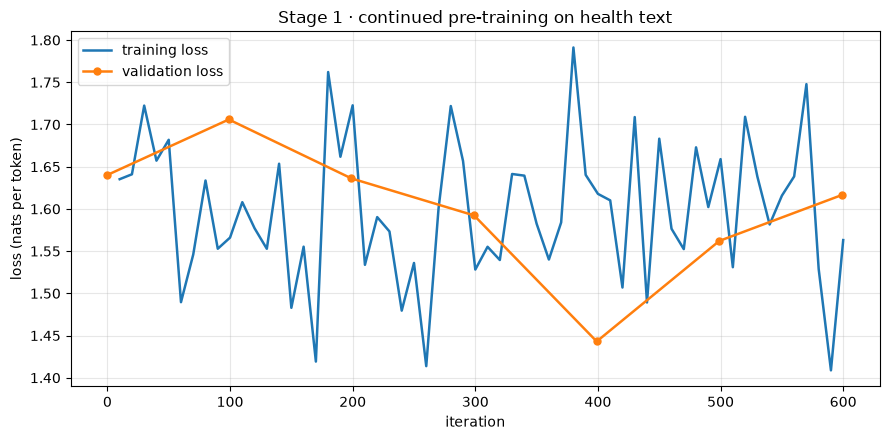

validation loss: 1.6402 → 1.6165  (-1.4%)
peak memory: 7.45 GB


In [10]:
plot_losses(
    cpt_recorder,
    title="Stage 1 · continued pre-training on health text",
    ylabel="loss (nats per token)",
    out_path=RESULTS_DIR / "cpt_loss.png",
)

**How to read this chart.** Both lines should slope downwards. A small, steady gap between
them is normal and healthy. If the validation line flattens or turns upward while the training
line keeps falling, the model has started memorising rather than generalising — the fix is
fewer iterations or a lower learning rate.

### 3c · Stage 2 — instruction tuning (practising answers)

Stage 2 continues from the Stage 1 adapter, so the health knowledge from the reading stage is
kept. Two things change: the data becomes question/answer pairs, and **only the answer counts
toward the loss**.

#### Why we render the prompt format ourselves

mlx-lm ships two dataset types for instruction data, `ChatDataset` and `CompletionsDataset`,
and **both call `tokenizer.apply_chat_template()`**. We deliberately use neither.

The decisive reason is **format parity between training and evaluation**. Our evaluation code
builds every prompt with `hl_lib.chatml()` — a fixed, hand-written ChatML rendering. If Stage 2
trained on the model's *own* template but evaluation used ours, Model C would be tested on a
format it had never been trained on, and would score worse than it deserves for a purely
cosmetic reason. One format, used everywhere, removes that whole failure mode.

A second, weaker reason: a *base* model cannot be relied on to ship a chat template at all.
(`Qwen3-1.7B-Base` happens to ship one — but depending on that is a trap for the next person
who swaps the model.)

So we render the ChatML ourselves, exactly as `hl_lib.chatml()` does everywhere else.

One detail that makes this exact: this tokenizer sets `add_bos_token: false` and has no BOS
token, so tokenising the prompt and the answer separately and concatenating the ids gives
precisely the same sequence as tokenising the whole string — and the boundary between them,
which is what the loss mask depends on, is unambiguous.

#### Still getting answer-only loss

mlx-lm's datasets return a tuple `(tokens, offset)`, where `offset` is the number of leading
tokens to *exclude* from the loss. Its `default_loss` masks every position before `offset`.
By returning the prompt length as the offset, we get loss on the **answer tokens only** —
the same thing PyTorch recipes achieve by setting prompt labels to `-100`.

Without this the model would waste capacity learning to predict the *question*, when what we
want is a better *answer*.

In [11]:
# Reload the base model so Stage 2 starts from clean weights, then re-attach LoRA
# and load the Stage 1 adapter into it — this is what makes Model C = Stage 1 + Stage 2.
model, tokenizer = load(MODEL)
model = attach_lora(model)
model.load_weights(str(ADAPTER_CPT / "adapters.safetensors"), strict=False)

print(f"\nloaded Stage 1 adapter from {ADAPTER_CPT}")

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 449.15it/s]


Trainable parameters: 2.026% (34.865M/1720.575M)

loaded Stage 1 adapter from /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/cpt


In [12]:
class ChatMLDataset:
    """Fixed ChatML rendering + loss on the assistant answer only.

    mlx-lm's ChatDataset and CompletionsDataset both call apply_chat_template(), which a
    base model may not have and which would differ from the format hl_lib.chatml() uses at
    evaluation time. We render the prompt ourselves so training and evaluation match.

    process() returns (tokens, offset) — mlx-lm's contract. `offset` is the prompt length,
    and default_loss() masks out every position before it, leaving loss on the answer only.
    """

    def __init__(self, data, tokenizer):
        self._data = data
        self.tokenizer = tokenizer

    def process(self, row):
        messages = row["messages"]

        # Everything up to and including "<|im_start|>assistant\n" is the prompt
        prompt = hl_lib.chatml(messages[:-1], add_generation_prompt=True)
        answer = messages[-1]["content"] + "<|im_end|>\n"

        # Tokenised separately, then concatenated — identical to the PyTorch recipe,
        # and it keeps the prompt/answer boundary exact.
        prompt_ids = self.tokenizer.encode(prompt, add_special_tokens=False)
        answer_ids = self.tokenizer.encode(answer, add_special_tokens=False)

        return (prompt_ids + answer_ids, len(prompt_ids))

    def __getitem__(self, idx):
        return self._data[idx]

    def __len__(self):
        return len(self._data)


sft_train_set = ChatMLDataset(sft_train, tokenizer)
sft_val_set   = ChatMLDataset(sft_val,   tokenizer)

# Sanity-check the masking on one example before training on 600 of them
sample_tokens, sample_offset = sft_train_set.process(sft_train[0])
print(f"Stage 2 training examples   : {len(sft_train_set):,}")
print(f"Stage 2 validation examples : {len(sft_val_set):,}")
print(f"\nexample 0: {len(sample_tokens)} tokens total, "
      f"{sample_offset} masked as prompt, "
      f"{len(sample_tokens) - sample_offset} scored as answer")
print("\nthe first tokens actually scored (should be the start of the answer):")
print(f"  {tokenizer.decode(sample_tokens[sample_offset:sample_offset + 24])!r}")

Stage 2 training examples   : 9,000
Stage 2 validation examples : 300

example 0: 226 tokens total, 131 masked as prompt, 95 scored as answer

the first tokens actually scored (should be the start of the answer):
  'Given his history of bilateral cryptorchidism, even though he underwent orchidopexy at 8 months old'


In [13]:
sft_args = TrainingArgs(
    batch_size=BATCH_SIZE,
    iters=SFT_ITERS,
    val_batches=VAL_BATCHES,
    steps_per_report=STEPS_PER_REPORT,
    steps_per_eval=STEPS_PER_EVAL,
    steps_per_save=STEPS_PER_EVAL,
    max_seq_length=SFT_MAX_LEN,
    adapter_file=ADAPTER_SFT / "adapters.safetensors",
    grad_checkpoint=GRAD_CHECKPOINT,
    grad_accumulation_steps=GRAD_ACCUM,
)

sft_recorder = LossRecorder()
model.train()

start = time.time()

train(
    model=model,
    optimizer=optim.AdamW(learning_rate=SFT_LR, weight_decay=0.01),
    train_dataset=CacheDataset(sft_train_set),
    val_dataset=CacheDataset(sft_val_set),
    args=sft_args,
    training_callback=sft_recorder,
)

print(f"\nStage 2 finished in {(time.time() - start) / 60:.1f} minutes")

sft_recorder.save(RESULTS_DIR / "sft_log.json")
save_adapter_config(ADAPTER_SFT)
print(f"Stage 2 adapter saved to {ADAPTER_SFT}")

Starting training..., iters: 600


Calculating loss...: 100%|██████████| 20/20 [00:34<00:00,  1.74s/it]

Iter 1: Val loss 1.927, Val took 34.828s


Iter 10: Train loss 2.336, Learning Rate 1.000e-04, It/sec 0.477, Tokens/sec 61.330, Trained Tokens 1285, Peak mem 7.663 GB
Iter 20: Train loss 1.656, Learning Rate 1.000e-04, It/sec 0.432, Tokens/sec 68.419, Trained Tokens 2870, Peak mem 7.942 GB
Iter 30: Train loss 1.675, Learning Rate 1.000e-04, It/sec 0.347, Tokens/sec 41.017, Trained Tokens 4051, Peak mem 7.997 GB
Iter 40: Train loss 1.704, Learning Rate 1.000e-04, It/sec 0.320, Tokens/sec 34.648, Trained Tokens 5133, Peak mem 7.997 GB
Iter 50: Train loss 1.769, Learning Rate 1.000e-04, It/sec 0.131, Tokens/sec 17.975, Trained Tokens 6504, Peak mem 7.997 GB
Iter 60: Train loss 1.477, Learning Rate 1.000e-04, It/sec 0.189, Tokens/sec 23.882, Trained Tokens 7770, Peak mem 7.997 GB
Iter 70: Train loss 1.367, Learning Rate 1.000e-04, It/sec 0.273, Tokens/sec 22.462, Trained Tokens 8592, Peak mem 7.997 GB
Iter 80: Train loss 1.407, Learning Rate 1.000e-04, It/sec 0.260, Tokens/sec 36.054, Trained Tokens 9980, Peak mem 7.997 GB
Iter 90:

Calculating loss...: 100%|██████████| 20/20 [00:22<00:00,  1.14s/it]

...

Iter 500: Val loss 1.467, Val took 27.014s


Iter 500: Train loss 1.318, Learning Rate 1.000e-04, It/sec 0.239, Tokens/sec 45.374, Trained Tokens 68085, Peak mem 9.119 GB
Iter 500: Saved adapter weights to /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/sft/adapters.safetensors and /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/sft/0000500_adapters.safetensors.
Iter 510: Train loss 1.340, Learning Rate 1.000e-04, It/sec 0.237, Tokens/sec 32.860, Trained Tokens 69471, Peak mem 9.119 GB
Iter 520: Train loss 1.708, Learning Rate 1.000e-04, It/sec 0.323, Tokens/sec 44.405, Trained Tokens 70845, Peak mem 9.119 GB
Iter 530: Train loss 1.363, Learning Rate 1.000e-04, It/sec 0.430, Tokens/sec 46.749, Trained Tokens 71932, Peak mem 9.119 GB
Iter 540: Train loss 1.637, Learning Rate 1.000e-04, It/sec 0.271, Tokens/sec 34.725, Trained Tokens 73214, Peak mem 9.119 GB
Iter 550: Train loss 1.341, Learning Rate 1.000e-04, It/sec 0.304, Tokens/sec 52.510, Trained Tokens 74944, Peak m

Calculating loss...: 100%|██████████| 20/20 [00:20<00:00,  1.03s/it]

Iter 600: Val loss 1.309, Val took 20.624s


Iter 600: Train loss 1.192, Learning Rate 1.000e-04, It/sec 0.233, Tokens/sec 30.881, Trained Tokens 83834, Peak mem 9.119 GB
Iter 600: Saved adapter weights to /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/sft/adapters.safetensors and /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/sft/0000600_adapters.safetensors.
Saved final weights to /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/sft/adapters.safetensors.

Stage 2 finished in 39.6 minutes
Stage 2 adapter saved to /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/adapters/sft


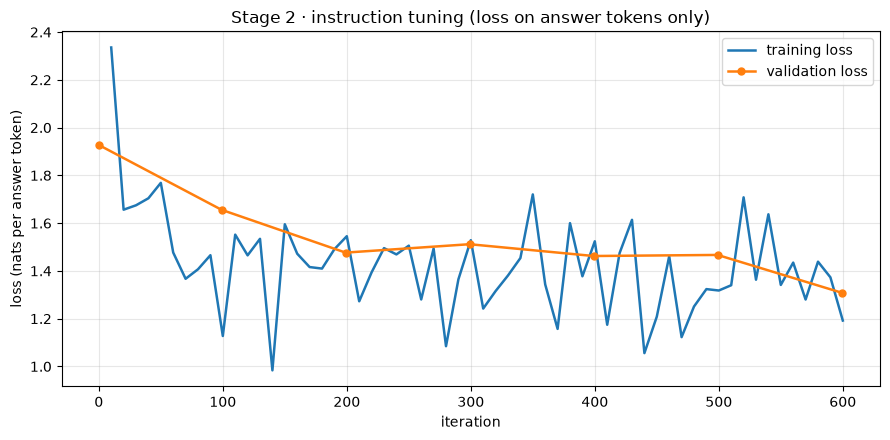

validation loss: 1.9272 → 1.3089  (-32.1%)
peak memory: 9.12 GB


In [14]:
plot_losses(
    sft_recorder,
    title="Stage 2 · instruction tuning (loss on answer tokens only)",
    ylabel="loss (nats per answer token)",
    out_path=RESULTS_DIR / "sft_loss.png",
)

> **Draft answer (Q3 — 2 to 3 paragraphs).** Describe the two stages and the settings: LoRA
> rank 32 with scale 2.0 on every transformer block, AdamW at 1e-4, an effective batch of 16
> blocks (batch 1 × 16 gradient-accumulation steps) of 2,048 tokens, trained locally on an
> Apple Silicon GPU through MLX. Then give the evidence: the validation loss before versus
> after Stage 1 (printed above), the training and validation curves falling together, the
> answer-only loss falling in Stage 2, and — from Step 5 — held-out perplexity dropping on
> unseen health text while WikiText-2 stays roughly flat. Quote the measured tokens/second and
> peak memory to show the run really fitted on the hardware.

---

# Step 4 · Q4. How did we evaluate?

> **In plain words.** We ask three versions of the model the same questions and compare.
> **A** is the untouched original, **B** has done the reading, **C** has done the reading *and*
> the practice. Three kinds of test: (1) how *surprised* is each model by health text it has
> never seen, (2) multiple-choice medical exam questions, (3) realistic patient stories whose
> answers we read ourselves. We also test on ordinary Wikipedia text, to check the model did
> not forget general English while learning medicine.

### The three tests

**1 · Perplexity** — the standard intrinsic score for a language model:

$$\text{Perplexity} = \exp\left(-\frac{1}{N}\sum_i \log P_\theta(x_i \mid x_{<i})\right)$$

Read it as *"the effective number of equally likely next tokens the model is choosing
between."* Lower is better. Perplexities are only comparable when the tokenizer and the text
are identical — which is why all three models use the same tokenizer and the same passages.

We score four held-out sets: **PubMed Central**, **MedlinePlus**, **Ghana STG/EML**, and
**WikiText-2**. The first three should go *down* from A to B if Stage 1 worked. The fourth is
the **control**: a large rise there would mean catastrophic forgetting.

**2 · Zero-shot multiple choice** — MedQA, MedMCQA and PubMedQA. For each question we append
`Answer:` and compare the model's next-token scores for the option letters. Nothing is
generated and nothing has to be parsed, which is fast and fair to a base model that might not
otherwise produce a cleanly formatted answer. We score two prompt styles (plain and chat) and
report the better, so no model is penalised for the wrong wrapper.

*Chance levels:* 25 % for MedQA and MedMCQA. PubMedQA is three-way (33 %), but always
answering "yes" scores about 55 %, so that is the bar that matters.

**3 · GP vignettes** — patient stories read side by side by a human. Does the answer name
plausible conditions? Mention red-flag symptoms? Suggest a sensible next step? Invent anything
dangerous?

### 4a · The evaluation functions

These are deliberately written out rather than hidden in a library — you need to be able to
explain them. Each is the MLX equivalent of the standard PyTorch recipe.

In [15]:
def perplexity(model, tokenizer, texts, max_len=PPL_MAX_LEN):
    """exp(mean negative log-likelihood per token) over `texts`. Lower is better."""
    model.eval()
    total_nll, total_tokens = 0.0, 0

    for text in texts:
        ids = tokenizer.encode(text)[:max_len]
        if len(ids) < 2:
            continue

        tokens = mx.array([ids])
        logits = model(tokens[:, :-1]).astype(mx.float32)   # predict token i+1 from token i
        targets = tokens[:, 1:]

        nll = nn.losses.cross_entropy(logits, targets, reduction="sum")
        mx.eval(nll)

        total_nll += nll.item()
        total_tokens += targets.size

    return math.exp(total_nll / total_tokens)


def mcq_accuracy(model, tokenizer, items, mode="plain"):
    """Zero-shot MCQ: pick the option letter with the highest next-token score."""
    model.eval()
    hits, totals = collections.Counter(), collections.Counter()

    for item in items:
        # The token id for each option letter, as it appears after a space
        letter_ids = [tokenizer.encode(" " + letter)[-1] for letter in item["letters"]]

        ids = tokenizer.encode(hl_lib.mcq_prompt_text(item, mode))[-3000:]
        logits = model(mx.array([ids]))[0, -1].astype(mx.float32)

        scores = mx.take(logits, mx.array(letter_ids))
        prediction = item["letters"][int(mx.argmax(scores).item())]

        hits[item["task"]] += (prediction == item["answer"])
        totals[item["task"]] += 1

    return {task: hits[task] / totals[task] for task in totals}


def answer_vignette(model, tokenizer, prompt, mode="chat", max_tokens=300):
    """Generate one GP-style answer, greedily (no sampling, so runs are reproducible)."""
    if mode == "chat":
        text = hl_lib.chatml(
            [{"role": "system", "content": hl_lib.SYSTEM},
             {"role": "user", "content": prompt}],
            add_generation_prompt=True,
        )
    else:
        text = f"Question: {prompt}\nAnswer:"

    out = generate(model, tokenizer, prompt=text, max_tokens=max_tokens, verbose=False)
    return out.split("<|im_end|>")[0].strip()


print("evaluation functions defined")

evaluation functions defined


### 4b · Score all three models

Each model is loaded fresh, scored on identical data, then released. **Model A loads no
adapter at all** — it is the original weights, untouched, which is what makes it a fair
baseline.

Results are written to `results/eval_results.json` after each model, so an interrupted run
resumes instead of starting over.

In [16]:
# Keep only the first N_MCQ questions per task, so every model sees identical questions
mcq_items = [
    item
    for task in ("MedQA", "MedMCQA", "PubMedQA")
    for item in [x for x in mcq_all if x["task"] == task][:N_MCQ]
]

ppl_sources = sorted({d["source"] for d in heldout})

# The three models under test: (label, adapter path or None for the untouched base)
MODELS_UNDER_TEST = [
    ("A · base",          None),
    ("B · +stage 1",      ADAPTER_CPT),
    ("C · +stage 1 + 2",  ADAPTER_SFT),
]

results_path = RESULTS_DIR / "eval_results.json"
results = json.loads(results_path.read_text()) if results_path.exists() else {}

print(f"scoring on {len(mcq_items)} exam questions, "
      f"{len(heldout)} held-out passages, {N_VIGNETTES} vignettes\n")

scoring on 600 exam questions, 402 held-out passages, 12 vignettes



In [17]:
for label, adapter_path in MODELS_UNDER_TEST:
    if label in results:
        print(f"{label}: already scored, skipping")
        continue

    print(f"\n{'=' * 70}\n{label}\n{'=' * 70}")
    started = time.time()

    # Load the base model; attach and load an adapter only for B and C
    eval_model, eval_tokenizer = load(MODEL)
    if adapter_path is not None:
        eval_model.freeze()
        linear_to_lora_layers(eval_model, NUM_LAYERS, LORA_CONFIG)
        eval_model.load_weights(str(adapter_path / "adapters.safetensors"), strict=False)
    eval_model.eval()

    entry = {}

    # 1 · Perplexity, per held-out source
    entry["perplexity"] = {}
    for source in ppl_sources:
        texts = [d["text"] for d in heldout if d["source"] == source]
        entry["perplexity"][source] = perplexity(eval_model, eval_tokenizer, texts)
        print(f"  perplexity · {source:<14} {entry['perplexity'][source]:8.2f}")

    # 2 · Multiple choice, in both prompt styles
    entry["mcq_plain"] = mcq_accuracy(eval_model, eval_tokenizer, mcq_items, "plain")
    entry["mcq_chat"]  = mcq_accuracy(eval_model, eval_tokenizer, mcq_items, "chat")
    for task in entry["mcq_plain"]:
        print(f"  accuracy   · {task:<14} "
              f"plain {entry['mcq_plain'][task]:.3f} | chat {entry['mcq_chat'][task]:.3f}")

    # 3 · Vignette answers, for reading by hand
    entry["generations"] = [
        answer_vignette(eval_model, eval_tokenizer, v["prompt"],
                        mode="chat" if label.startswith("C") else "plain")
        for v in vignettes[:N_VIGNETTES]
    ]

    results[label] = entry
    results_path.write_text(json.dumps(results, indent=1))

    print(f"  done in {(time.time() - started) / 60:.1f} min")

    del eval_model, eval_tokenizer
    mx.clear_cache()

print(f"\nall results saved to {results_path}")


A · base


Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 560.21it/s]


  perplexity · medlineplus        4.63
  perplexity · pmc_oa             5.73
  perplexity · wikitext2         11.79
  accuracy   · MedQA          plain 0.480 | chat 0.475
  accuracy   · MedMCQA        plain 0.490 | chat 0.400
  accuracy   · PubMedQA       plain 0.615 | chat 0.655
  done in 35.2 min

B · +stage 1


Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 529.22it/s]


  perplexity · medlineplus        4.48
  perplexity · pmc_oa             5.01
  perplexity · wikitext2         11.96
  accuracy   · MedQA          plain 0.455 | chat 0.470
  accuracy   · MedMCQA        plain 0.505 | chat 0.435
  accuracy   · PubMedQA       plain 0.605 | chat 0.665
  done in 34.2 min

C · +stage 1 + 2


Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 600.09it/s]


  perplexity · medlineplus        4.59
  perplexity · pmc_oa             5.09
  perplexity · wikitext2         11.98
  accuracy   · MedQA          plain 0.440 | chat 0.415
  accuracy   · MedMCQA        plain 0.490 | chat 0.500
  accuracy   · PubMedQA       plain 0.535 | chat 0.545
  done in 66.9 min

all results saved to /Users/eugenedev/Documents/SchoolOps/NLP_Projects/HealthLM/health-llm/results/eval_results.json


> **Draft answer (Q4 — 1 to 2 paragraphs).** We compared three models on identical held-out
> data: the untouched base (A), the base plus Stage 1 (B), and the base plus both stages (C).
> The intrinsic evaluation was perplexity on held-out PubMed Central, MedlinePlus and Ghana
> STG/EML passages, with WikiText-2 as a forgetting control. The extrinsic evaluation was
> zero-shot multiple-choice accuracy on MedQA, MedMCQA and PubMedQA, scored by comparing the
> next-token scores of the option letters and reporting the better of two prompt formats, plus
> a hand-read comparison of answers to GP vignettes. Held-out data was separated before
> training, and the multiple-choice evaluation uses the *test/validation* splits of datasets
> whose *train* splits were used in Stage 2.

---

# Step 5 · Q5. What results did we get?

Everything below is computed from *your* run. Nothing is hard-coded, and nothing should be
written into the report until these cells have actually produced numbers.

### Reading the numbers honestly

**The margin of error matters.** With `N` questions and accuracy `p`, the 95 % margin is
roughly `1.96 × √(p(1−p)/N)`. At `N = 200` and `p = 0.5` that is **±6.9 points**. A three-point
difference between two models is *not* a result — it is noise. The cell below prints the
margin for your actual `N` so you can quote it.

**A modest gain is a legitimate finding.** The base model has already read a great deal of
biomedical text during its original pre-training. If our two stages move the needle only a
little on exam questions, that is a real and reportable result, not a failure. Say so plainly
rather than overclaiming.

In [18]:
def best_accuracy(label, task):
    """A model is credited with the better of its two prompt formats."""
    return max(results[label]["mcq_plain"][task], results[label]["mcq_chat"][task])


labels = [label for label, _ in MODELS_UNDER_TEST if label in results]
tasks = ["MedQA", "MedMCQA", "PubMedQA"]

# ── Table 1 · held-out perplexity ─────────────────────────────────────────────
print("TABLE 1 · Held-out perplexity (lower is better)\n")
header = f"{'model':<20}" + "".join(f"{s:>16}" for s in ppl_sources)
print(header)
print("-" * len(header))
for label in labels:
    row = f"{label:<20}" + "".join(f"{results[label]['perplexity'][s]:>16.2f}" for s in ppl_sources)
    print(row)

# ── Table 2 · multiple-choice accuracy ────────────────────────────────────────
print(f"\n\nTABLE 2 · Zero-shot accuracy, N = {N_MCQ} per task (higher is better)\n")
header = f"{'model':<20}" + "".join(f"{t:>14}" for t in tasks)
print(header)
print("-" * len(header))
print(f"{'chance / majority':<20}" + f"{'25.0%':>14}{'25.0%':>14}{'~55.0%':>14}")
for label in labels:
    row = f"{label:<20}" + "".join(f"{100 * best_accuracy(label, t):>13.1f}%" for t in tasks)
    print(row)

margin = 1.96 * math.sqrt(0.25 / N_MCQ) * 100
print(f"\n95% margin of error at p=0.5, N={N_MCQ}: ±{margin:.1f} points")
print("Differences smaller than this should NOT be reported as improvements.")

TABLE 1 · Held-out perplexity (lower is better)

model                    medlineplus          pmc_oa       wikitext2
--------------------------------------------------------------------
A · base                        4.63            5.73           11.79
B · +stage 1                    4.48            5.01           11.96
C · +stage 1 + 2                4.59            5.09           11.98


TABLE 2 · Zero-shot accuracy, N = 200 per task (higher is better)

model                        MedQA       MedMCQA      PubMedQA
--------------------------------------------------------------
chance / majority            25.0%         25.0%        ~55.0%
A · base                     48.0%         49.0%         65.5%
B · +stage 1                 47.0%         50.5%         66.5%
C · +stage 1 + 2             44.0%         50.0%         54.5%

95% margin of error at p=0.5, N=200: ±6.9 points
Differences smaller than this should NOT be reported as improvements.


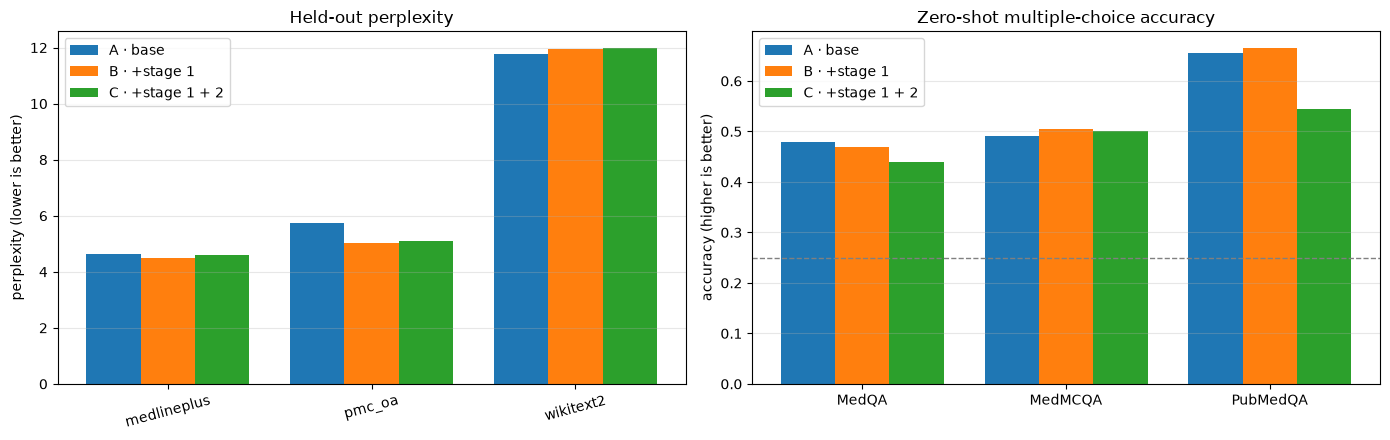

In [19]:
# ── Figure · perplexity and accuracy side by side ─────────────────────────────
import numpy as np

fig, (ax_ppl, ax_acc) = plt.subplots(1, 2, figsize=(14, 4.5))
width = 0.8 / max(len(labels), 1)

for i, label in enumerate(labels):
    positions = np.arange(len(ppl_sources)) + i * width
    ax_ppl.bar(positions, [results[label]["perplexity"][s] for s in ppl_sources],
               width, label=label)

ax_ppl.set_xticks(np.arange(len(ppl_sources)) + width)
ax_ppl.set_xticklabels(ppl_sources, rotation=15)
ax_ppl.set_ylabel("perplexity (lower is better)")
ax_ppl.set_title("Held-out perplexity")
ax_ppl.legend()
ax_ppl.grid(axis="y", alpha=0.3)

for i, label in enumerate(labels):
    positions = np.arange(len(tasks)) + i * width
    ax_acc.bar(positions, [best_accuracy(label, t) for t in tasks], width, label=label)

ax_acc.axhline(0.25, linestyle="--", linewidth=1, color="grey")
ax_acc.set_xticks(np.arange(len(tasks)) + width)
ax_acc.set_xticklabels(tasks)
ax_acc.set_ylabel("accuracy (higher is better)")
ax_acc.set_title("Zero-shot multiple-choice accuracy")
ax_acc.legend()
ax_acc.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "eval_summary.png", dpi=150)
plt.show()

In [20]:
# ── The sentences for your Q5 paragraph ───────────────────────────────────────
if len(labels) >= 2:
    base_label, cpt_label = labels[0], labels[1]

    print("PERPLEXITY — effect of Stage 1 (A → B)\n")
    for source in ppl_sources:
        before = results[base_label]["perplexity"][source]
        after = results[cpt_label]["perplexity"][source]
        change = 100 * (after / before - 1)
        note = "  ← general-English control" if source == "wikitext2" else ""
        print(f"  {source:<14} {before:8.2f} → {after:8.2f}   {change:+6.1f}%{note}")

if len(labels) >= 3:
    print("\n\nACCURACY — across all three models\n")
    for task in tasks:
        values = "  →  ".join(f"{100 * best_accuracy(l, task):.1f}%" for l in labels)
        print(f"  {task:<12} {values}")
    print(f"\n  (remember: ±{margin:.1f} points is noise at N={N_MCQ})")

PERPLEXITY — effect of Stage 1 (A → B)

  medlineplus        4.63 →     4.48     -3.3%
  pmc_oa             5.73 →     5.01    -12.6%
  wikitext2         11.79 →    11.96     +1.4%  ← general-English control


ACCURACY — across all three models

  MedQA        48.0%  →  47.0%  →  44.0%
  MedMCQA      49.0%  →  50.5%  →  50.0%
  PubMedQA     65.5%  →  66.5%  →  54.5%

  (remember: ±6.9 points is noise at N=200)


### The GP vignettes, side by side

**Read these yourself — this is the qualitative half of the evaluation.** For each case, ask:

- Does the answer name a **plausible condition**?
- Does it mention **red-flag symptoms** that need urgent care?
- Does it suggest a **sensible next step**?
- Does it invent anything **unsafe** — a drug, a dose, a diagnosis?

Watch particularly for the difference between A and C. A base model tends to *continue* the
text of the prompt; an instruction-tuned one tends to *answer* it in a structured way. Record
your judgements in a simple table for the report (Appendix C of the report has a scoring
sheet).

In [21]:
for i, vignette in enumerate(vignettes[:N_VIGNETTES]):
    print("=" * 100)
    print(f"VIGNETTE {i + 1}")
    print("=" * 100)
    print(f"PATIENT: {vignette['prompt']}\n")

    for label in labels:
        answer = results[label]["generations"][i].replace("\n", " ")
        print(f"  ── {label} ──")
        print(f"  {answer[:700]}\n")

VIGNETTE 1
PATIENT: A 4-year-old child in a rural village in Northern Ghana has had fever for 3 days with chills, vomiting and refuses to eat. He is very sleepy today. What could be going on and what should be done?

  ── A · base ──
  The child is most likely suffering from malaria. Malaria is a disease caused by a parasite that is transmitted to humans by the bite of an infected mosquito. The symptoms of malaria include fever, chills, vomiting, and fatigue. The child should be taken to a healthcare provider for diagnosis and treatment. The healthcare provider may prescribe antimalarial medication to treat the infection. It is important to prevent the spread of malaria by using insect repellent and wearing long-sleeved clothing and long pants when outdoors.

  ── B · +stage 1 ──
  The child is most likely suffering from malaria. Malaria is a disease caused by a parasite that is transmitted to humans by the bite of an infected mosquito. The parasite is found in the blood of infected mo

> **How to write the answer (Q5 — 1 to 2 paragraphs).** Use the printed numbers, not
> impressions. Say whether perplexity fell on the three health sets and by how much; say what
> happened on WikiText-2 (roughly flat means no catastrophic forgetting). Report the
> multiple-choice accuracy for A, B and C against the chance baseline, and state the margin of
> error before claiming any difference is real. Add one sentence from the vignettes — for
> example, that structure and red-flag advice appear after Stage 2. A 1.7 B model will not
> match large medical models on MedQA; do not imply that it does.

---

# Step 6 · Q6. What else should we know?

> **In plain words.** This is a **school exercise, not a doctor.** It can be confidently
> wrong — which is more dangerous than being obviously wrong. Never use it for a real medical
> decision.

### Limitations

- **Not a clinical tool.** No clinician validated any output. Exam accuracy measures exam
  knowledge, not consultation quality, and the vignette judgements are subjective.
- **A small, single run.** One seed, one pass over the data, a modest token budget. Differences
  of a point or two are inside run-to-run noise.
- **Compute shaped the scope.** We train on a fraction of the ~19 M tokens available because a
  laptop is the limiting factor. More tokens, or a larger model, is the obvious next step and
  an honest "future work" item.
- **The base model has seen medicine before.** Much biomedical text is in any modern model's
  pre-training data, so measurable gains may be modest. That is a finding, not a failure.
- **Benchmark leakage cannot be ruled out.** We never trained on the test splits, but the base
  model's original web-scale pre-training may have included public benchmark text.
- **English only, and skewed.** PubMed over-represents research-country populations. Conditions
  and drug availability common in rural Ghana may be under-represented, and no Ghanaian
  language is covered. Nothing here measures fairness across groups.
- **Guidelines age.** The Ghana STG/EML we used is the 2017 edition; a newer edition supersedes
  it. Record the edition and year whenever you cite it.

### Ethics

Health is a high-stakes domain, and the specific risks are worth naming:

- **Hallucination and over-confidence.** A small model can invent a drug dose in fluent,
  authoritative prose. Fluency is not accuracy.
- **Privacy.** We deliberately avoided datasets scraped from patient–doctor chat sites.
- **Equity.** Whose health data is represented shapes who the model serves well.
- **Transparency and accountability.** It must be clear to any user that this is a program and
  not a clinician, and a human professional must stay in the loop.

**What we did about it:** licensed, non-personal data with the licence recorded per document;
an explicit "general information, not a substitute for a clinician" system prompt; evaluation
on data separated before training; and honest reporting of the limits above.

**What we would add next:** clinician review of the outputs, hard-coded red-flag rules that
override the model, alignment training (RLHF or DPO) for safe refusals, and retrieval with
citations so claims can be checked against the guidelines.

> **Draft answer (Q6 — 1 to 3 paragraphs).** Choose the three points that matter most to your
> team. The strongest are: the not-a-clinical-tool caveat, the small single run, and the
> honest statement that the base model already knew a lot of medicine so the attributable gain
> is modest.

---

## Reproducing this work

```
collect.py  →  prep.py  →  this notebook
```

Artefacts this notebook writes:

| Path | What it is |
|:--|:--|
| `adapters/cpt/adapters.safetensors` | Stage 1 adapter (Model B) |
| `adapters/sft/adapters.safetensors` | Stage 1 + 2 adapter (Model C) |
| `results/cpt_log.json`, `results/sft_log.json` | Loss curves as raw numbers |
| `results/cpt_loss.png`, `results/sft_loss.png` | Figures 3 and 4 for the report |
| `results/eval_results.json` | Every number in Step 5 |
| `results/eval_summary.png` | Figure 5 for the report |

The base model is never modified, so **Model A is exactly recoverable** by loading `MODEL`
with no adapter. Everything else is reproducible from the base download plus the two small
adapter files.